In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.stats import mannwhitneyu

NL = chr(10)
EXTRACT_DIR = './stro_clean'
os.makedirs(EXTRACT_DIR, exist_ok=True)

for zp_candidates, target in [
    (['./doorvaarten.csv.zip', './data/doorvaarten.csv.zip', '/content/doorvaarten.csv.zip'], 'doorvaarten.csv'),
    (['./ladingen.csv.zip', './data/ladingen.csv.zip', '/content/ladingen.csv.zip'], 'ladingen.csv')
]:
    out_path = os.path.join(EXTRACT_DIR, target)
    if not os.path.exists(out_path):
        zp_found = next((p for p in zp_candidates if os.path.exists(p)), None)
        if zp_found is None:
            raise FileNotFoundError(f"Archive for {target} not found in {zp_candidates}")
        print(f"Extracting {target} from {zp_found}...")
        with zipfile.ZipFile(zp_found, 'r') as zf:
            with zf.open(target) as src, open(out_path, 'wb') as dst:
                dst.write(src.read())

df_d = pd.read_csv(os.path.join(EXTRACT_DIR, 'doorvaarten.csv'), sep=';', encoding='utf-8', low_memory=False)
df_l = pd.read_csv(os.path.join(EXTRACT_DIR, 'ladingen.csv'), sep=';', encoding='utf-8', low_memory=False)

def safe_zscore(M_arr):
    mean_v = np.mean(M_arr, axis=0)
    std_v = np.std(M_arr, axis=0, ddof=1)
    safe_std = np.where(std_v > 1e-12, std_v, 1.0)
    Z = (M_arr - mean_v) / safe_std
    Z[:, std_v <= 1e-12] = 0.0
    return Z

def compute_first_echelon(dlnX, n_boot=300, sample_frac=0.8, seed=42):
    Z = safe_zscore(dlnX)
    M, N = Z.shape
    U, s, Vt = np.linalg.svd(Z, full_matrices=False)
    u1 = np.take(U, 0, axis=1)
    v1 = np.take(Vt, 0, axis=0)
    u2 = np.take(U, 1, axis=1)
    v2 = np.take(Vt, 1, axis=0)
    var1 = (s.item(0)**2) / np.sum(s**2) * 100.0
    var2 = (s.item(1)**2) / np.sum(s**2) * 100.0
    pr_u1 = (1.0 / np.sum(u1**4) - 1.0) / (M - 1.0)
    pr_v1 = (1.0 / np.sum(v1**4) - 1.0) / (N - 1.0)

    rng = np.random.default_rng(seed)
    sub_M = int(np.floor(M * sample_frac))
    boot_pru, boot_prv = [], []
    for _ in range(n_boot):
        idx = np.sort(rng.choice(M, size=sub_M, replace=False))
        Zb = safe_zscore(dlnX[idx, :])
        Ub, _, Vtb = np.linalg.svd(Zb, full_matrices=False)
        u1b = np.take(Ub, 0, axis=1)
        v1b = np.take(Vtb, 0, axis=0)
        boot_pru.append((1.0 / np.sum(u1b**4) - 1.0) / (sub_M - 1.0))
        boot_prv.append((1.0 / np.sum(v1b**4) - 1.0) / (N - 1.0))

    return {
        'var1': var1, 'var2': var2,
        'pr_u1': pr_u1, 'pru_ci': np.percentile(boot_pru, [2.5, 97.5]),
        'pr_v1': pr_v1, 'prv_ci': np.percentile(boot_prv, [2.5, 97.5]),
        'u1': u1, 'v1': v1, 'u2': u2, 'v2': v2
    }

def compute_second_echelon(dlnX, k_nn=8, min_seg=15):
    Z = safe_zscore(dlnX)
    M, N = Z.shape
    dist_mat = squareform(pdist(Z, metric='euclidean'))
    sigma_med = np.median(dist_mat[np.triu_indices(M, k=1)])
    W_full = np.exp(-(dist_mat**2) / (2.0 * sigma_med**2))
    np.fill_diagonal(W_full, 0.0)
    A = np.zeros((M, M))
    for i in range(M):
        nn_idx = np.argsort(dist_mat[i, :])[1:k_nn+1]
        for j in nn_idx:
            A[i, j] = W_full[i, j]
            A[j, i] = W_full[j, i]
    deg = np.sum(A, axis=1)
    d_inv_sqrt = np.diag(1.0 / np.sqrt(np.maximum(deg, 1e-12)))
    L_sym = np.eye(M) - d_inv_sqrt @ A @ d_inv_sqrt
    eigvals, eigvecs = np.linalg.eigh(L_sym)
    psi2 = np.take(eigvecs, 1, axis=1)
    if np.mean(psi2[:M//2]) > np.mean(psi2[M//2:]):
        psi2 = -psi2
    best_p, best_tau = 1.0, -1
    for tau in range(min_seg, M - min_seg):
        _, pval = mannwhitneyu(psi2[:tau], psi2[tau:], alternative='two-sided')
        if pval < best_p:
            best_p, best_tau = pval, tau
    return eigvals[:5], psi2, best_tau, best_p

print(f"Loaded {len(df_d):,} passages and {len(df_l):,} cargo records.")


Extracting doorvaarten.csv from ./doorvaarten.csv.zip...
Extracting ladingen.csv from ./ladingen.csv.zip...
Loaded 2,152,670 passages and 5,568,590 cargo records.


In [2]:
d_sub = df_d[['id_doorvaart', 'jaar', 'schipper_plaatsnaam']].copy()
d_sub['jaar'] = pd.to_numeric(d_sub['jaar'], errors='coerce')
d_sub = d_sub[(d_sub['jaar'] >= 1700) & (d_sub['jaar'] <= 1856)].dropna(subset=['jaar'])
d_sub['jaar'] = d_sub['jaar'].astype(int)

m_df = df_l[['id_doorvaart', 'van', 'naar', 'soort']].merge(d_sub, on='id_doorvaart', how='inner')
print(f"1700-1856 Sample: {len(m_df):,} cargo records across {m_df['id_doorvaart'].nunique():,} unique passages.")

def classify_port(s):
    if not isinstance(s, str): return None
    low = s.strip().lower()
    if low in ['', '-', '?'] or ' og ' in low or 'sidst' in low or 'fra ' in low: return None
    if 'londonderry' in low or 'londondery' in low or 'ny archangel' in low or 'nye archangel' in low: return None
    if any(k in low for k in ['petersb', 'pietersb']): return 'St_Petersburg'
    if low.startswith('riga'): return 'Riga'
    if low.startswith('narv') or low.startswith('narw') or low == 'der narwa': return 'Narva'
    if any(k in low for k in ['wyborg', 'viborg', 'vyborg', 'wiborg']): return 'Vyborg'
    if any(k in low for k in ['pernau', 'pernow']): return 'Pernau'
    if any(k in low for k in ['reval', 'revel']): return 'Reval'
    if any(k in low for k in ['libau', 'windau']): return 'Libau_Windau'
    if any(k in low for k in ['dantzi', 'danzig', 'dansch']): return 'Gdansk'
    if any(k in low for k in ['konigsb', 'kønigsb', 'koenigsb', 'pillau']): return 'Konigsberg'
    if 'memel' in low: return 'Memel'
    if 'stettin' in low: return 'Stettin'
    if 'rostock' in low: return 'Rostock'
    if 'stockholm' in low: return 'Stockholm'
    if any(k in low for k in ['gothenb', 'gottenb']): return 'Gothenburg'
    if any(k in low for k in ['kiøben', 'kjøben', 'copenhag', 'kioben']): return 'Copenhagen'
    if 'amsterd' in low: return 'Amsterdam'
    if 'rotterd' in low: return 'Rotterdam'
    if low.startswith('london'): return 'London'
    if low.startswith('hull'): return 'Hull'
    if 'newcastle' in low or 'nycastel' in low: return 'Newcastle'
    if 'dundee' in low: return 'Dundee'
    if 'bordeaux' in low: return 'Bordeaux'
    if any(k in low for k in ['lissab', 'lisbon']): return 'Lisbon'
    return None

m_df['dep_clean'] = m_df['van'].map(classify_port)
passages_port = m_df.dropna(subset=['dep_clean']).drop_duplicates(subset=['id_doorvaart', 'dep_clean'])
piv = passages_port.pivot_table(index='jaar', columns='dep_clean', values='id_doorvaart', aggfunc='count', fill_value=0)
piv = piv.reindex(range(1700, 1857), fill_value=0)

CORE_PORTS = [
    'St_Petersburg', 'Riga', 'Narva', 'Vyborg', 'Libau_Windau', 'Pernau', 'Reval',
    'Gdansk', 'Konigsberg', 'Memel', 'Stettin', 'Rostock',
    'Stockholm', 'Gothenburg', 'Copenhagen',
    'Amsterdam', 'Rotterdam', 'London', 'Hull', 'Bordeaux'
]

YRS_22_56 = np.arange(1722, 1857)
X_ports = piv.loc[1722:1856, CORE_PORTS].to_numpy(dtype=float)
dlnX_ports = np.diff(np.log1p(X_ports), axis=0)
trans_yrs = YRS_22_56[1:]

# 1. Full 1722-1856 Spectral & Graph Audit
res_full = compute_first_echelon(dlnX_ports)
_, psi2_full, tau_full, p_full = compute_second_echelon(dlnX_ports, k_nn=8, min_seg=15)

# 2. Peace-Time Spectral Audit (Excluding 1807-1814 & 1854-1856)
war_blockade_yrs = {1807, 1808, 1809, 1810, 1811, 1812, 1813, 1814, 1854, 1855, 1856}
peace_mask = np.array([int(y) not in war_blockade_yrs for y in trans_yrs])
dlnX_peace = dlnX_ports[peace_mask, :]
res_peace = compute_first_echelon(dlnX_peace)
_, psi2_peace, tau_peace, p_peace = compute_second_echelon(dlnX_peace, k_nn=8, min_seg=15)

# 3. Russian Imperial Ports Sub-Panel (7 ports, 1722-1856)
RUS_PORTS = ['St_Petersburg', 'Riga', 'Narva', 'Vyborg', 'Libau_Windau', 'Pernau', 'Reval']
X_rus = piv.loc[1722:1856, RUS_PORTS].to_numpy(dtype=float)
dlnX_rus = np.diff(np.log1p(X_rus), axis=0)
res_rus_full = compute_first_echelon(dlnX_rus)
res_rus_peace = compute_first_echelon(dlnX_rus[peace_mask, :])

print("\n=== TABLE 1: SUMMARY OF BALTIC & RUSSIAN PORT NETWORK (1722-1856) ===")
print(f"Full 20-Port Network (M=134)   | Var1: {res_full['var1']:.1f}% | PR(u1): {res_full['pr_u1']:.3f} [{res_full['pru_ci'].item(0):.3f}, {res_full['pru_ci'].item(1):.3f}] | PR(v1): {res_full['pr_v1']:.3f} [{res_full['prv_ci'].item(0):.3f}, {res_full['prv_ci'].item(1):.3f}] | Split: {int(trans_yrs.item(tau_full))} (p={p_full:.3f})")
print(f"Peace-Time 20-Port (M=123)     | Var1: {res_peace['var1']:.1f}% | PR(u1): {res_peace['pr_u1']:.3f} [{res_peace['pru_ci'].item(0):.3f}, {res_peace['pru_ci'].item(1):.3f}] | PR(v1): {res_peace['pr_v1']:.3f} [{res_peace['prv_ci'].item(0):.3f}, {res_peace['prv_ci'].item(1):.3f}] | Split: {int(trans_yrs[peace_mask].item(tau_peace))} (p={p_peace:.3f})")
print(f"Russian 7-Port Full (M=134)    | Var1: {res_rus_full['var1']:.1f}% | PR(u1): {res_rus_full['pr_u1']:.3f} | PR(v1): {res_rus_full['pr_v1']:.3f}")
print(f"Russian 7-Port Peace (M=123)   | Var1: {res_rus_peace['var1']:.1f}% | PR(u1): {res_rus_peace['pr_u1']:.3f} | PR(v1): {res_rus_peace['pr_v1']:.3f}")

# 4. Extended Flag Mimicry Check (with Scottish & English outports included)
rus_pass = m_df[m_df['dep_clean'].isin(['St_Petersburg', 'Riga'])].drop_duplicates(subset=['id_doorvaart']).copy()
def classify_flag_ext(s):
    if not isinstance(s, str): return 'Continental_Neutral'
    low = s.strip().lower()
    uk_kw = ['london', 'hull', 'newcastle', 'dundee', 'leith', 'liverpool', 'leverpool', 'whitby',
             'sunderland', 'yarmouth', 'lynn', 'montrose', 'arbroath', 'shields', 'aberdeen',
             'peterhead', 'kirkaldy', 'perth', 'scarbro', 'bristol', 'glasgow', 'belfast']
    if any(k in low for k in uk_kw): return 'British'
    if any(k in low for k in ['boston', 'new york', 'philadelph', 'baltimore', 'salem', 'charleston', 'america']): return 'American_US'
    if any(k in low for k in ['petersb', 'riga', 'reval', 'narva', 'wyborg', 'viborg', 'libau', 'windau', 'pernau']): return 'Russian_Baltic'
    return 'Continental_Neutral'

rus_pass['flag_ext'] = rus_pass['schipper_plaatsnaam'].map(classify_flag_ext)
ct_f = pd.crosstab(rus_pass.loc[rus_pass['jaar'].between(1805, 1815), 'jaar'],
                   rus_pass.loc[rus_pass['jaar'].between(1805, 1815), 'flag_ext'])
print("\n=== EXTENDED FLAG MIMICRY ON ST. PETERSBURG & RIGA (1805-1815) ===")
print(ct_f.to_string())

# 5. Grain-Carrying Passages During European Crisis Years (Bridge to Study 1)
grain_regex = '^(?:rug|rogg|hved|hued|weizen|byg|gerst|havr|haver)'
m_grain = m_df[
    (m_df['jaar'].between(1729, 1855)) &
    (m_df['dep_clean'].isin(['Gdansk', 'Konigsberg', 'Riga', 'St_Petersburg', 'Memel', 'Stettin'])) &
    (m_df['soort'].fillna('').str.strip().str.lower().str.contains(grain_regex, regex=True))
].drop_duplicates(subset=['id_doorvaart', 'dep_clean'])

piv_grain = m_grain.pivot_table(index='jaar', columns='dep_clean', values='id_doorvaart', aggfunc='count', fill_value=0)
piv_grain = piv_grain.reindex(range(1729, 1856), fill_value=0)
ev_yrs = list(map(int, '1741 1771 1795 1817 1847'.split()))
comp_g = piv_grain.loc[ev_yrs].copy()
comp_g['Total_6_Ports'] = comp_g.sum(axis=1)
print("\n=== GRAIN-CARRYING SHIPS IN CRISIS YEARS (Long-run mean = 774/yr) ===")
print(comp_g.to_string())


1700-1856 Sample: 3,637,322 cargo records across 1,274,843 unique passages.

=== TABLE 1: SUMMARY OF BALTIC & RUSSIAN PORT NETWORK (1722-1856) ===
Full 20-Port Network (M=134)   | Var1: 37.9% | PR(u1): 0.033 [0.020, 0.066] | PR(v1): 0.854 [0.704, 0.877] | Split: 1775 (p=0.350)
Peace-Time 20-Port (M=123)     | Var1: 20.8% | PR(u1): 0.133 [0.095, 0.188] | PR(v1): 0.539 [0.500, 0.573] | Split: 1836 (p=0.231)
Russian 7-Port Full (M=134)    | Var1: 60.8% | PR(u1): 0.032 | PR(v1): 0.867
Russian 7-Port Peace (M=123)   | Var1: 28.2% | PR(u1): 0.259 | PR(v1): 0.718

=== EXTENDED FLAG MIMICRY ON ST. PETERSBURG & RIGA (1805-1815) ===
flag_ext  American_US  British  Continental_Neutral  Russian_Baltic
jaar                                                               
1805               35      647                  893              24
1806               39      648                  628              27
1807                1      368                  129              20
1808                0        

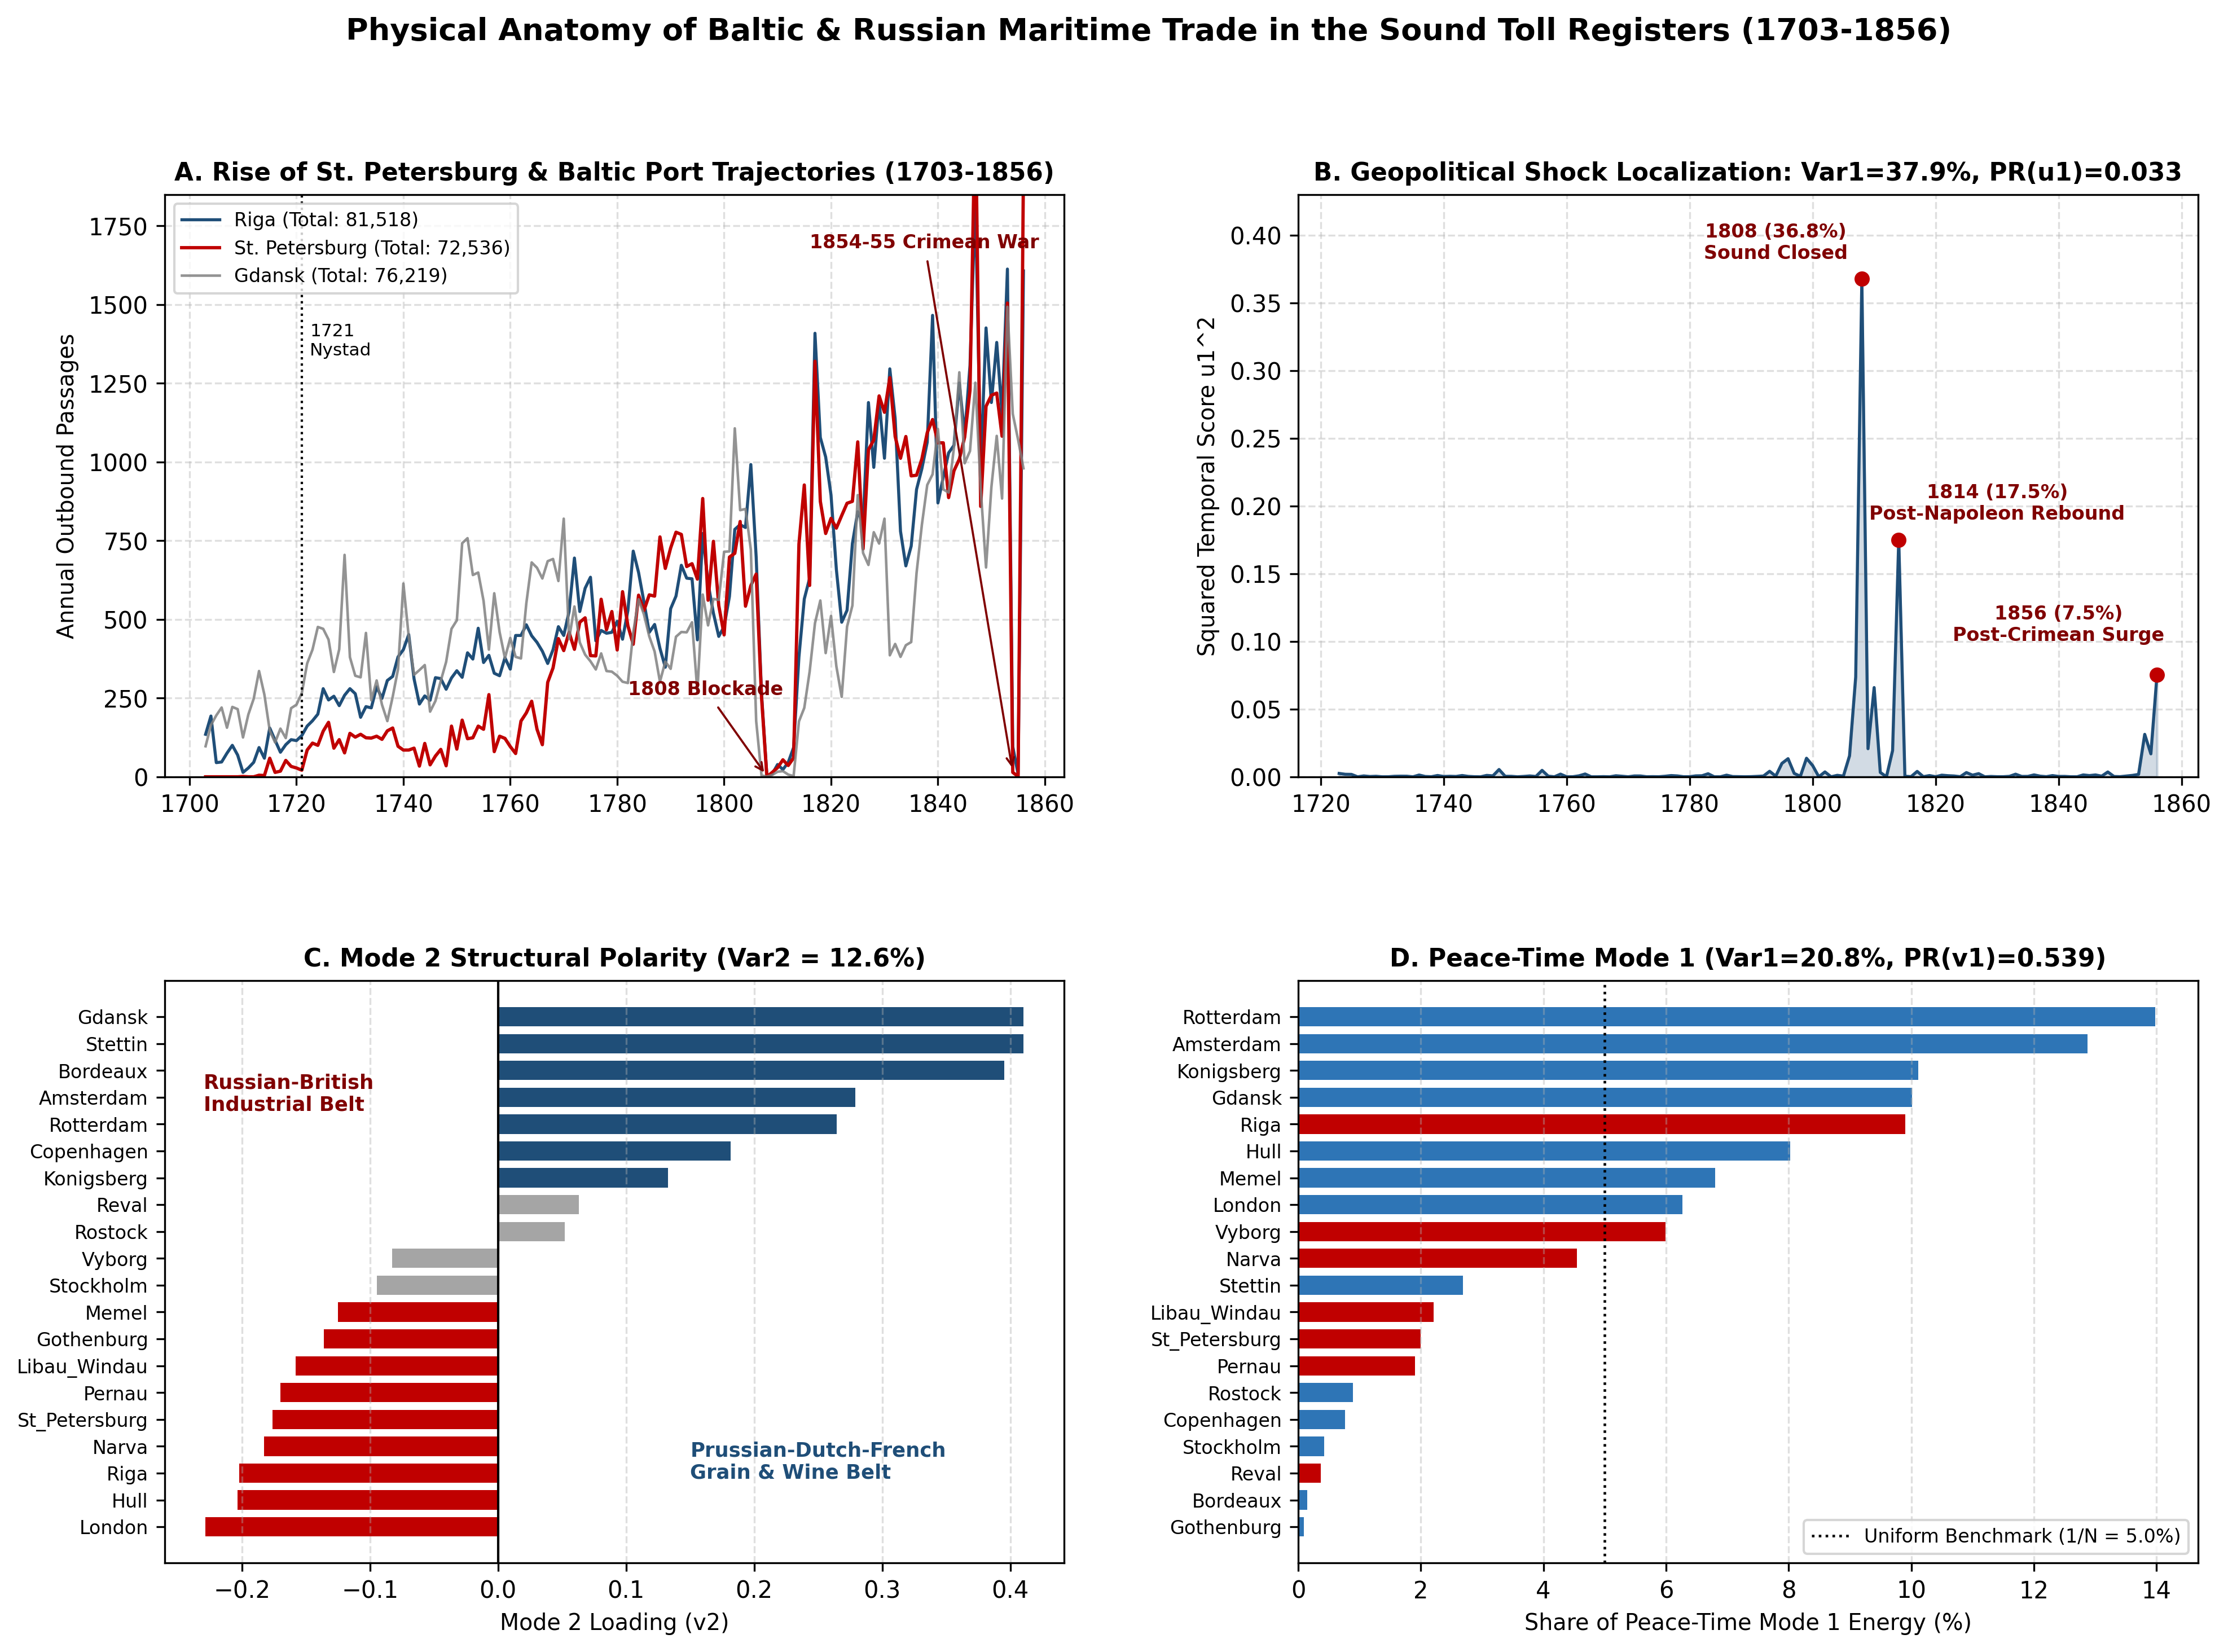

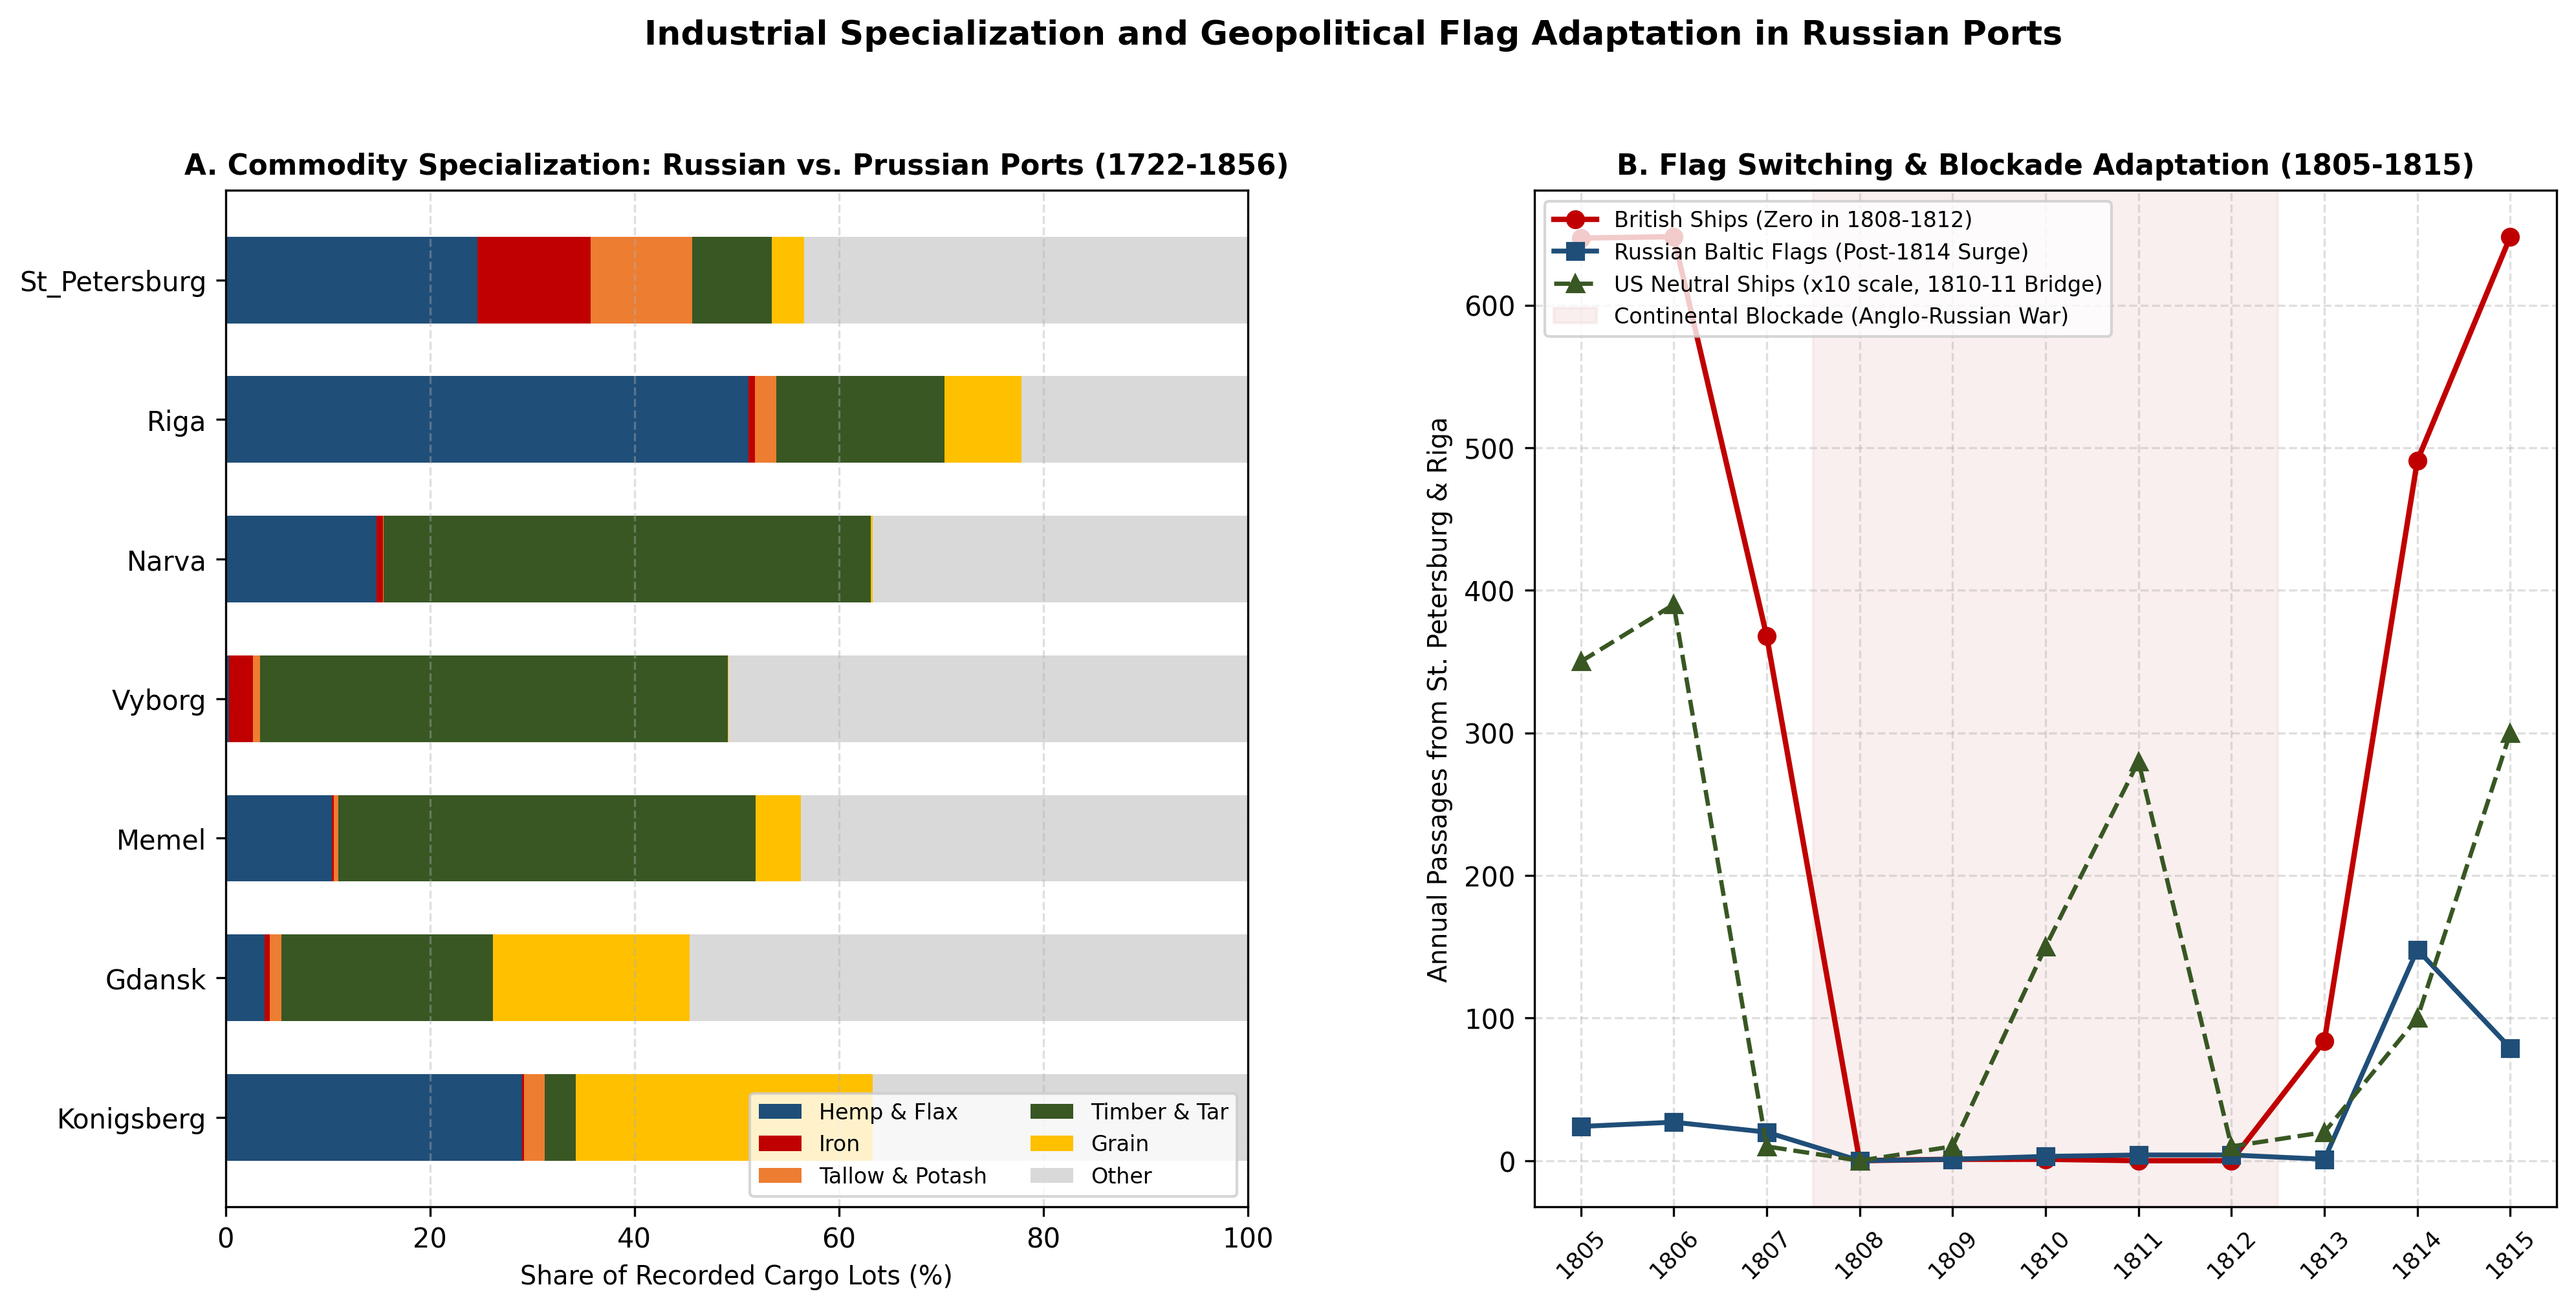

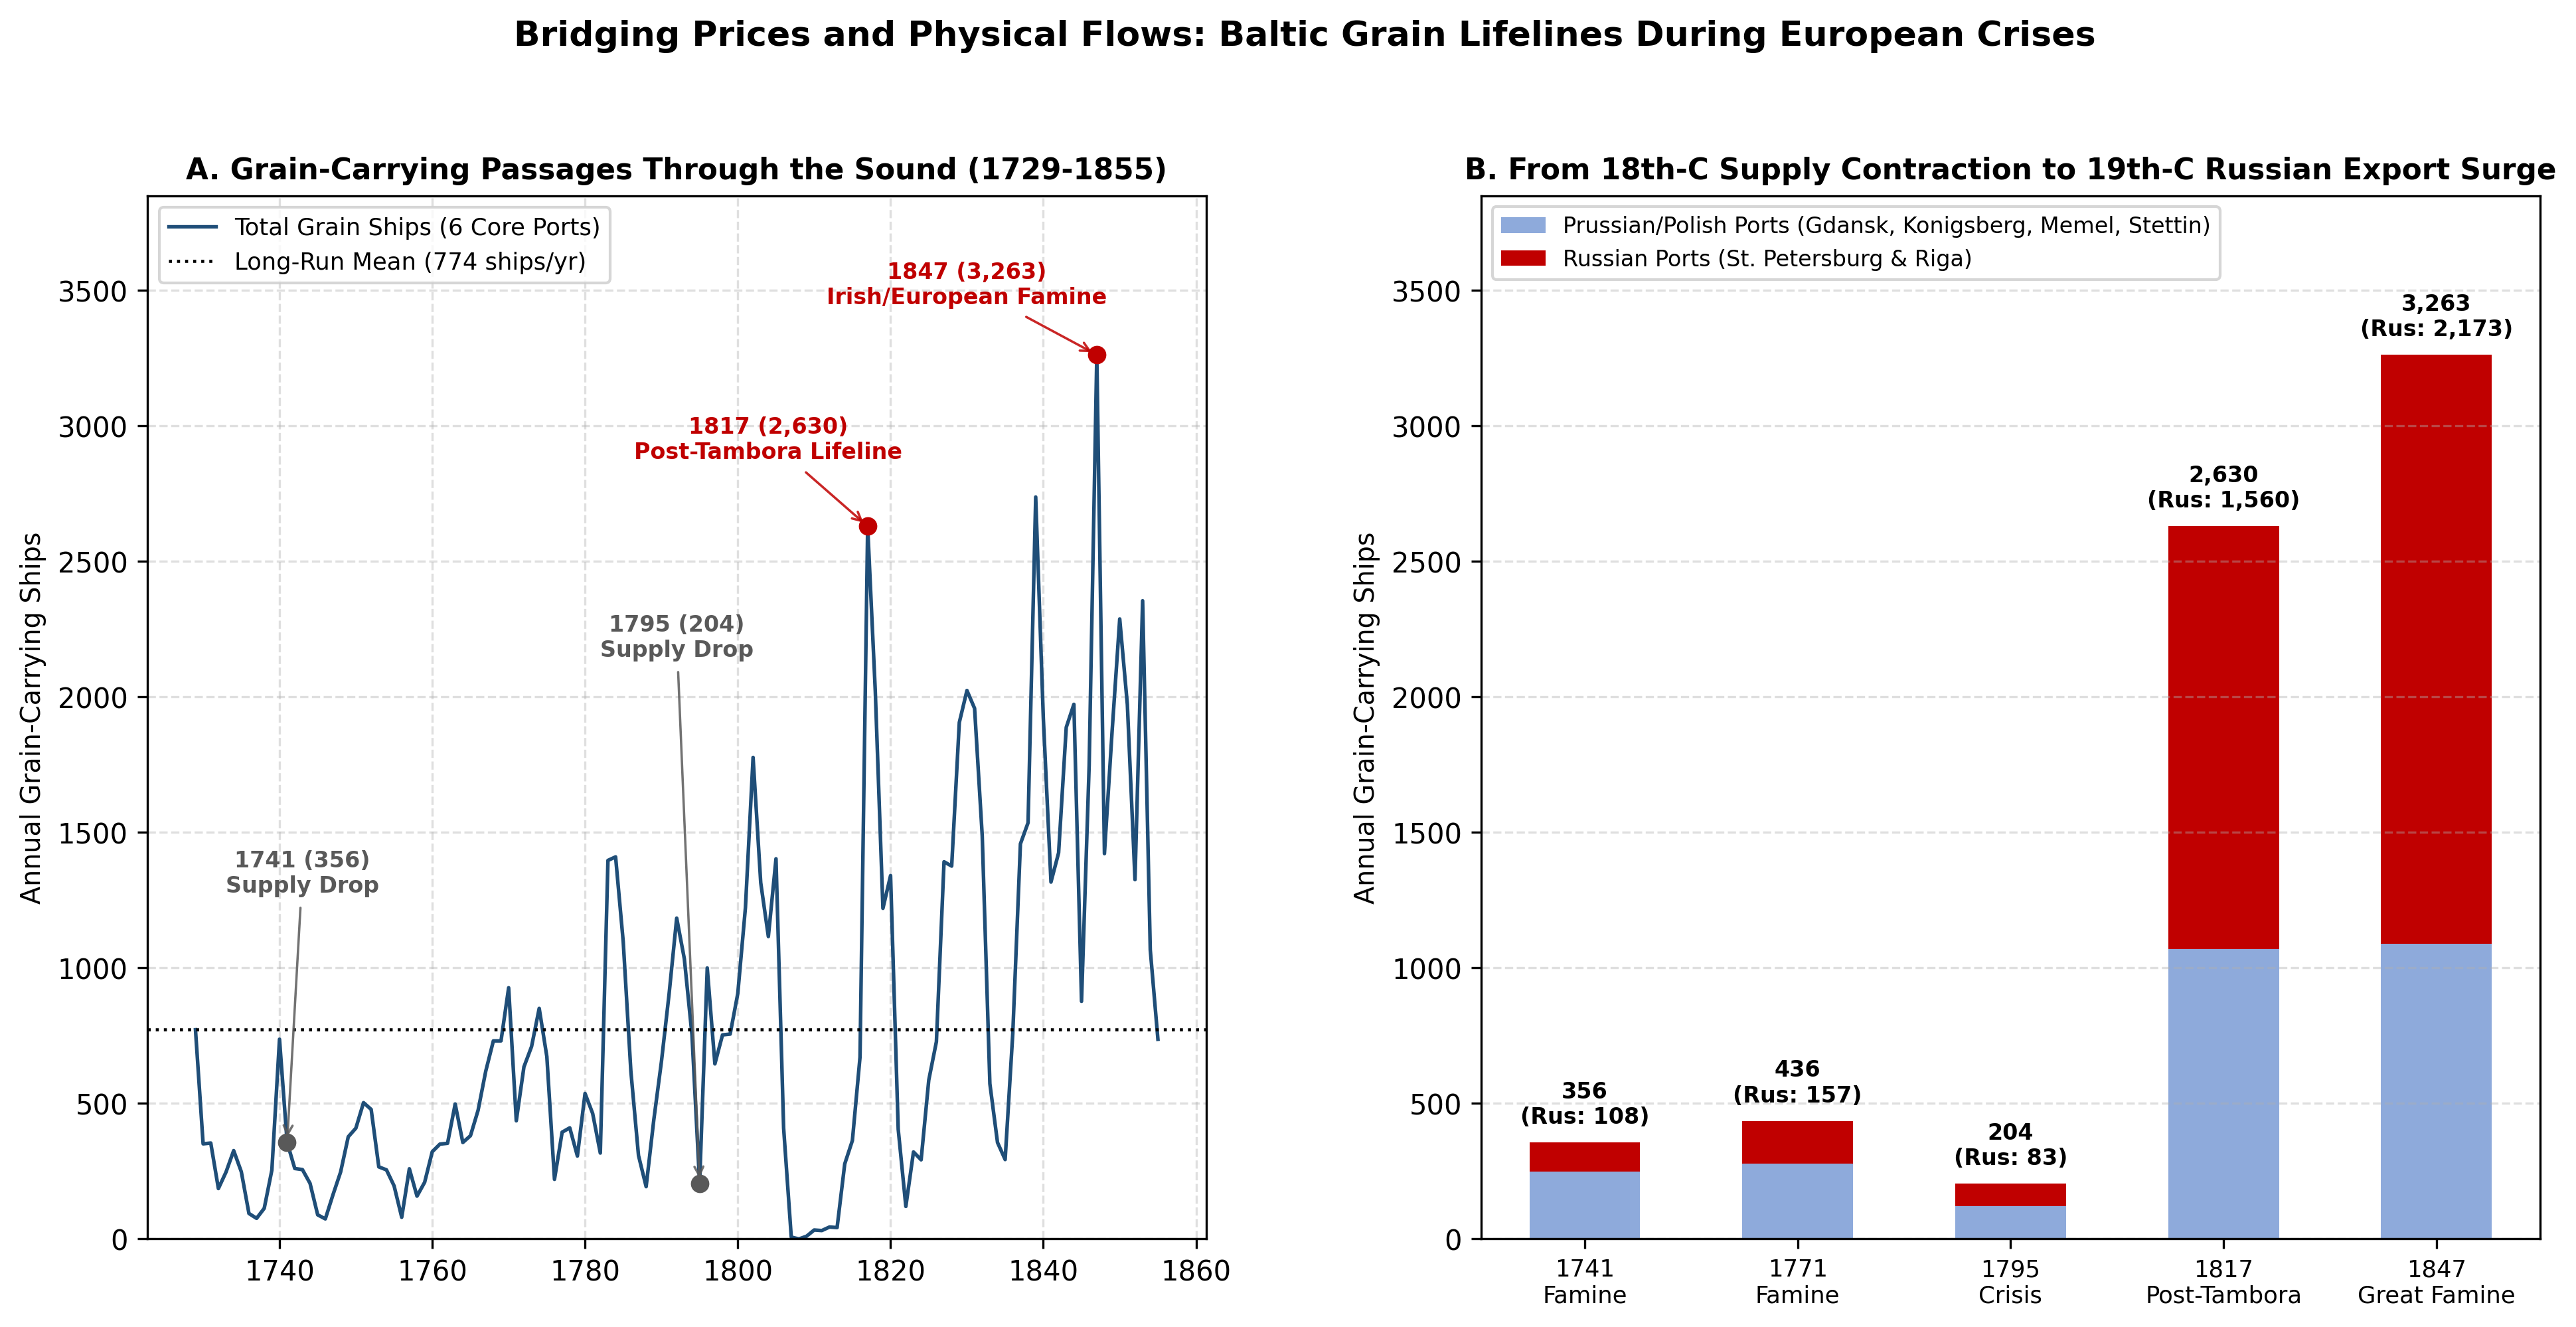

Saved Figure_1_STRO.png, Figure_2_STRO.png, and Figure_3_STRO.png successfully!


In [3]:
# --- FIGURE 1: Port Emergence, Blockade Shocks & Peace vs War Decomposition ---
fig1 = plt.figure(figsize=(15.5, 10.5), dpi=300)
plt.subplots_adjust(hspace=0.35, wspace=0.26)

ax1 = fig1.add_subplot(2, 2, 1)
yrs_all = np.arange(1703, 1857)
ax1.plot(yrs_all, piv.loc[1703:1856, 'Riga'], color='#1f4e78', lw=1.3, label='Riga (Total: 81,518)')
ax1.plot(yrs_all, piv.loc[1703:1856, 'St_Petersburg'], color='#c00000', lw=1.4, label='St. Petersburg (Total: 72,536)')
ax1.plot(yrs_all, piv.loc[1703:1856, 'Gdansk'], color='#808080', lw=1.1, alpha=0.85, label='Gdansk (Total: 76,219)')
ax1.axvline(1721, color='black', linestyle=':', lw=1.0)
ax1.text(1722.5, 1340, '1721' + NL + 'Nystad', fontsize=7.5, color='black')
ax1.annotate('1808 Blockade', xy=(1808, 2), xytext=(1782, 260),
             arrowprops=dict(arrowstyle='->', color='#800000', lw=0.9), fontsize=8, fontweight='bold', color='#800000')
ax1.annotate('1854-55 Crimean War', xy=(1854, 15), xytext=(1816, 1680),
             arrowprops=dict(arrowstyle='->', color='#800000', lw=0.9), fontsize=8, fontweight='bold', color='#800000')
ax1.set_title("A. Rise of St. Petersburg & Baltic Port Trajectories (1703-1856)", fontsize=10.5, fontweight='bold')
ax1.set_ylabel("Annual Outbound Passages", fontsize=9.5)
ax1.set_ylim(0, 1850)
ax1.legend(loc='upper left', fontsize=8)
ax1.grid(True, linestyle='--', alpha=0.4)

ax2 = fig1.add_subplot(2, 2, 2)
u1_sq = res_full['u1']**2
ax2.plot(trans_yrs, u1_sq, color='#1f4e78', lw=1.3)
ax2.fill_between(trans_yrs, 0, u1_sq, color='#1f4e78', alpha=0.2)
for yr, lbl, dx, dy in [
    (1808, '1808 (36.8%)' + NL + 'Sound Closed', -14, 0.015),
    (1814, '1814 (17.5%)' + NL + 'Post-Napoleon Rebound', 16, 0.015),
    (1856, '1856 (7.5%)' + NL + 'Post-Crimean Surge', -16, 0.025)
]:
    idx_a, = np.where(trans_yrs == yr)
    v_y = float(u1_sq.item(int(idx_a.item(0))))
    ax2.scatter([yr], [v_y], color='#c00000', s=30, zorder=5)
    ax2.annotate(lbl, xy=(yr, v_y), xytext=(yr + dx, v_y + dy), ha='center', fontsize=8, fontweight='bold', color='#800000')
ax2.set_title(f"B. Geopolitical Shock Localization: Var1={res_full['var1']:.1f}%, PR(u1)={res_full['pr_u1']:.3f}", fontsize=10.5, fontweight='bold')
ax2.set_ylabel("Squared Temporal Score u1^2", fontsize=9.5)
ax2.set_ylim(0, 0.43)
ax2.grid(True, linestyle='--', alpha=0.4)

ax3 = fig1.add_subplot(2, 2, 3)
df_v2 = pd.DataFrame({'Port': CORE_PORTS, 'v2': res_full['v2']}).sort_values(by='v2', ascending=True)
colors_v2 = ['#c00000' if x < -0.10 else ('#1f4e78' if x > 0.10 else '#a5a5a5') for x in df_v2['v2']]
ax3.barh(df_v2['Port'], df_v2['v2'], color=colors_v2, height=0.72)
ax3.axvline(0, color='black', lw=1.0)
ax3.text(-0.23, 15.5, 'Russian-British' + NL + 'Industrial Belt', fontsize=8.5, fontweight='bold', color='#800000')
ax3.text(0.15, 1.8, 'Prussian-Dutch-French' + NL + 'Grain & Wine Belt', fontsize=8.5, fontweight='bold', color='#1f4e78')
ax3.set_title(f"C. Mode 2 Structural Polarity (Var2 = {res_full['var2']:.1f}%)", fontsize=10.5, fontweight='bold')
ax3.set_xlabel("Mode 2 Loading (v2)", fontsize=9.5)
ax3.tick_params(axis='y', labelsize=8)
ax3.grid(True, axis='x', linestyle='--', alpha=0.4)

ax4 = fig1.add_subplot(2, 2, 4)
df_p1 = pd.DataFrame({'Port': CORE_PORTS, 'pct': (res_peace['v1']**2) * 100.0}).sort_values(by='pct', ascending=True)
colors_p1 = ['#c00000' if p in RUS_PORTS else '#2e75b6' for p in df_p1['Port']]
ax4.barh(df_p1['Port'], df_p1['pct'], color=colors_p1, height=0.72)
ax4.axvline(5.0, color='black', linestyle=':', lw=1.1, label='Uniform Benchmark (1/N = 5.0%)')
ax4.set_title(f"D. Peace-Time Mode 1 (Var1={res_peace['var1']:.1f}%, PR(v1)={res_peace['pr_v1']:.3f})", fontsize=10.5, fontweight='bold')
ax4.set_xlabel("Share of Peace-Time Mode 1 Energy (%)", fontsize=9.5)
ax4.tick_params(axis='y', labelsize=8)
ax4.legend(loc='lower right', fontsize=8)
ax4.grid(True, axis='x', linestyle='--', alpha=0.4)

fig1.suptitle("Physical Anatomy of Baltic & Russian Maritime Trade in the Sound Toll Registers (1703-1856)", fontsize=13, fontweight='bold', y=0.98)
plt.savefig('Figure_1_STRO.png', bbox_inches='tight')
plt.show()
plt.close(fig1)

# --- FIGURE 2: Commodity Specialization & Flag Mimicry During Blockades ---
fig2 = plt.figure(figsize=(15.5, 6.8), dpi=300)
plt.subplots_adjust(wspace=0.28)

def classify_comm(s):
    if not isinstance(s, str): return 'Other'
    low = s.strip().lower()
    if any(k in low for k in ['rug', 'rogg', 'hved', 'hued', 'weizen', 'byg', 'gerst', 'havr', 'haver']): return 'Grain'
    if any(k in low for k in ['hamp', 'hemp', 'hennep', 'hør', 'hor', 'blaar', 'flax']): return 'Hemp & Flax'
    if any(k in low for k in ['jern', 'iron', 'ijzer']): return 'Iron'
    if any(k in low for k in ['bielk', 'bjelk', 'bræd', 'braed', 'plank', 'staver', 'clapholt', 'deel', 'mast', 'spar', 'tiære', 'tjaere', 'beg']): return 'Timber & Tar'
    if any(k in low for k in ['tælle', 'taelle', 'talg', 'asche', 'potas']): return 'Tallow & Potash'
    return 'Other'

ports_spec = ['St_Petersburg', 'Riga', 'Narva', 'Vyborg', 'Memel', 'Gdansk', 'Konigsberg']
m_spec = m_df[(m_df['jaar'] >= 1722) & (m_df['dep_clean'].isin(ports_spec))].copy()
m_spec['comm_group'] = m_spec['soort'].map(classify_comm)
ct_spec = pd.crosstab(m_spec['dep_clean'], m_spec['comm_group'], normalize='index').loc[ports_spec] * 100.0

ax1 = fig2.add_subplot(1, 2, 1)
comm_order = ['Hemp & Flax', 'Iron', 'Tallow & Potash', 'Timber & Tar', 'Grain', 'Other']
comm_colors = ['#1f4e78', '#c00000', '#ed7d31', '#385723', '#ffc000', '#d9d9d9']
bottom_vals = np.zeros(len(ports_spec))
for c_name, col in zip(comm_order, comm_colors):
    vals = ct_spec[c_name].to_numpy()
    ax1.barh(ports_spec[::-1], vals[::-1], left=bottom_vals[::-1], color=col, height=0.62, label=c_name)
    bottom_vals += vals
ax1.set_xlim(0, 100)
ax1.set_xlabel("Share of Recorded Cargo Lots (%)", fontsize=9.5)
ax1.set_title("A. Commodity Specialization: Russian vs. Prussian Ports (1722-1856)", fontsize=10.5, fontweight='bold')
ax1.legend(loc='lower right', fontsize=8, ncol=2)
ax1.grid(True, axis='x', linestyle='--', alpha=0.4)

ax2 = fig2.add_subplot(1, 2, 2)
yrs_nap = np.arange(1805, 1816)
ct_f = ct_f.reindex(yrs_nap, fill_value=0)
ax2.plot(yrs_nap, ct_f['British'], color='#c00000', lw=2.0, marker='o', label='British Ships (Zero in 1808-1812)')
ax2.plot(yrs_nap, ct_f['Russian_Baltic'], color='#1f4e78', lw=1.8, marker='s', label='Russian Baltic Flags (Post-1814 Surge)')
ax2.plot(yrs_nap, ct_f['American_US'] * 10, color='#385723', lw=1.6, linestyle='--', marker='^', label='US Neutral Ships (x10 scale, 1810-11 Bridge)')
ax2.axvspan(1807.5, 1812.5, color='#f2dcdb', alpha=0.45, label='Continental Blockade (Anglo-Russian War)')
ax2.set_xticks(yrs_nap)
ax2.set_xticklabels(yrs_nap, rotation=45, fontsize=8.5)
ax2.set_ylabel("Annual Passages from St. Petersburg & Riga", fontsize=9.5)
ax2.set_title("B. Flag Switching & Blockade Adaptation (1805-1815)", fontsize=10.5, fontweight='bold')
ax2.legend(loc='upper left', fontsize=8)
ax2.grid(True, linestyle='--', alpha=0.4)

fig2.suptitle("Industrial Specialization and Geopolitical Flag Adaptation in Russian Ports", fontsize=12.5, fontweight='bold', y=1.01)
plt.savefig('Figure_2_STRO.png', bbox_inches='tight')
plt.show()
plt.close(fig2)

# --- FIGURE 3: Grain Lifelines Through the Sound (1729-1855) ---
fig3 = plt.figure(figsize=(15.5, 6.8), dpi=300)
plt.subplots_adjust(wspace=0.26)

ax1 = fig3.add_subplot(1, 2, 1)
yrs_g = np.arange(1729, 1856)
tot_g = piv_grain.sum(axis=1)
ax1.plot(yrs_g, tot_g, color='#1f4e78', lw=1.3, label='Total Grain Ships (6 Core Ports)')
ax1.axhline(tot_g.mean(), color='black', linestyle=':', lw=1.1, label=f'Long-Run Mean ({tot_g.mean():.0f} ships/yr)')

for yr, lbl, xy_t in [
    (1741, '1741 (356)' + NL + 'Supply Drop', (1743, 1280)),
    (1795, '1795 (204)' + NL + 'Supply Drop', (1792, 2150)),
    (1817, '1817 (2,630)' + NL + 'Post-Tambora Lifeline', (1804, 2880)),
    (1847, '1847 (3,263)' + NL + 'Irish/European Famine', (1830, 3450))
]:
    val_g = int(tot_g.loc[yr])
    col_pt = '#c00000' if val_g > 2000 else '#595959'
    ax1.scatter([yr], [val_g], color=col_pt, s=32, zorder=5)
    ax1.annotate(lbl, xy=(yr, val_g), xytext=xy_t,
                 arrowprops=dict(arrowstyle='->', color=col_pt, lw=0.85, alpha=0.85),
                 ha='center', fontsize=8, fontweight='bold', color=col_pt)

ax1.set_title("A. Grain-Carrying Passages Through the Sound (1729-1855)", fontsize=10.5, fontweight='bold')
ax1.set_ylabel("Annual Grain-Carrying Ships", fontsize=9.5)
ax1.set_ylim(0, 3850)
ax1.legend(loc='upper left', fontsize=8.5)
ax1.grid(True, linestyle='--', alpha=0.4)

ax2 = fig3.add_subplot(1, 2, 2)
events = ['1741' + NL + 'Famine', '1771' + NL + 'Famine', '1795' + NL + 'Crisis', '1817' + NL + 'Post-Tambora', '1847' + NL + 'Great Famine']
prussian_g = (piv_grain.loc[ev_yrs, 'Gdansk'] + piv_grain.loc[ev_yrs, 'Konigsberg'] + piv_grain.loc[ev_yrs, 'Memel'] + piv_grain.loc[ev_yrs, 'Stettin']).to_numpy()
russian_g  = (piv_grain.loc[ev_yrs, 'Riga'] + piv_grain.loc[ev_yrs, 'St_Petersburg']).to_numpy()

x_e = np.arange(len(events))
ax2.bar(x_e, prussian_g, width=0.52, color='#8eaadb', label='Prussian/Polish Ports (Gdansk, Konigsberg, Memel, Stettin)')
ax2.bar(x_e, russian_g, bottom=prussian_g, width=0.52, color='#c00000', label='Russian Ports (St. Petersburg & Riga)')
for i, (p_v, r_v) in enumerate(zip(prussian_g, russian_g)):
    ax2.text(i, p_v + r_v + 70, f"{p_v + r_v:,}" + NL + f"(Rus: {r_v:,})", ha='center', fontsize=8, fontweight='bold')
ax2.set_xticks(x_e)
ax2.set_xticklabels(events, fontsize=8.5)
ax2.set_ylim(0, 3850)
ax2.set_ylabel("Annual Grain-Carrying Ships", fontsize=9.5)
ax2.set_title("B. From 18th-C Supply Contraction to 19th-C Russian Export Surge", fontsize=10.5, fontweight='bold')
ax2.legend(loc='upper left', fontsize=8)
ax2.grid(True, axis='y', linestyle='--', alpha=0.4)

fig3.suptitle("Bridging Prices and Physical Flows: Baltic Grain Lifelines During European Crises", fontsize=12.5, fontweight='bold', y=1.01)
plt.savefig('Figure_3_STRO.png', bbox_inches='tight')
plt.show()
plt.close(fig3)
print("Saved Figure_1_STRO.png, Figure_2_STRO.png, and Figure_3_STRO.png successfully!")